# Лабораторна робота №2: Мультимодальна інженерія та відбір ознак

Цей блокнот містить кроки з виконання екстракції ознак, автоматичного синтезу, моделювання 5 експериментів (зокрема Експеримент 4 із пасткою витоку) та відбору ознак.

In [3]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, accuracy_score, recall_score, precision_score
from sklearn.inspection import permutation_importance
from sklearn.feature_selection import SelectKBest, f_classif
from mlxtend.feature_selection import SequentialFeatureSelector

import featuretools as ft

import warnings
warnings.filterwarnings('ignore')

# Встановлюємо seed для відтворюваності розбиттів
SEED = 42

## 0. Завантаження та підготовка даних

In [4]:
# # Зчитування та дедуплікація
# # df = pd.read_excel('E Commerce Dataset.xlsx', sheet_name='E Comm')
# # Зчитування та дедуплікація
# df = pd.read_excel('E Commerce Dataset.xlsx', sheet_name='E Comm')
# df.columns = df.columns.str.strip()
# print(f"Оригінальна розмірність: {df.shape}")
#
# # Дедуплікація (видалення 556 рядків)
# df = df.drop_duplicates().reset_index(drop=True)
# print(f"Розмірність після дедуплікації: {df.shape}")

import os

# Перевіряємо, де лежить файл: у поточній папці чи на рівень вище
file_name = 'E Commerce Dataset.xlsx'
file_path = f"../{file_name}" if not os.path.exists(file_name) else file_name

# Зчитування та дедуплікація
df = pd.read_excel(file_path, sheet_name='E Comm')
df.columns = df.columns.str.strip()
print(f"Оригінальна розмірність: {df.shape}")

# Дедуплікація (видалення 556 рядків)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Розмірність після дедуплікації: {df.shape}")

Оригінальна розмірність: (5630, 20)
Розмірність після дедуплікації: (5630, 20)


## 1. Базові та ручні ознаки
Імпортуємо наші класи та налаштовуємо пайплайни.

In [5]:
# Цільова змінна
y = df['Churn']
X = df.drop(columns=['Churn', 'CustomerID'])

# Імпортуємо класи з нашого модуля (якщо вони в src/features.py)
# Для блокнота визначаємо їх тут, щоб усе працювало одразу
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import KFold
import pandas as pd
import numpy as np

class OOFWoEEncoder(BaseEstimator, TransformerMixin):
    def __init__(self, cv=5, smoothing=0.5):
        self.cv = cv
        self.smoothing = smoothing
        self.global_woe_ = {}
        
    def fit(self, X, y):
        y_sr = pd.Series(y)
        X_sr = pd.Series(X.ravel())
        counts = X_sr.value_counts()
        pos_counts = y_sr.groupby(X_sr).sum()
        p_event = (pos_counts + self.smoothing) / (y_sr.sum() + 2 * self.smoothing)
        p_non_event = ((counts - pos_counts) + self.smoothing) / ((len(y_sr) - y_sr.sum()) + 2 * self.smoothing)
        self.global_woe_ = np.log(p_event / p_non_event).to_dict()
        return self

    def fit_transform(self, X, y):
        self.fit(X, y)
        y_sr = pd.Series(y)
        X_sr = pd.Series(X.ravel())
        oof_encoded = np.zeros(len(X))
        kf = KFold(n_splits=self.cv, shuffle=True, random_state=SEED)
        
        for train_idx, val_idx in kf.split(X):
            X_train, y_train = X_sr.iloc[train_idx], y_sr.iloc[train_idx]
            counts = X_train.value_counts()
            pos_counts = y_train.groupby(X_train).sum()
            p_e = (pos_counts + self.smoothing) / (y_train.sum() + 2 * self.smoothing)
            p_n = ((counts - pos_counts) + self.smoothing) / ((len(y_train) - y_train.sum()) + 2 * self.smoothing)
            fold_woe = np.log(p_e / p_n).to_dict()
            oof_encoded[val_idx] = X_sr.iloc[val_idx].map(fold_woe).fillna(0)
            
        return oof_encoded.reshape(-1, 1)

    def transform(self, X):
        X_sr = pd.Series(np.array(X).ravel())
        return X_sr.map(self.global_woe_).fillna(0).values.reshape(-1, 1)

# Простий обробник для Baseline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

numeric_cols = ['Tenure', 'CashbackAmount', 'OrderCount']
categorical_cols = ['PreferredPaymentMode', 'MaritalStatus']

preprocessor = ColumnTransformer([
    ('num', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), numeric_cols),
    ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('ohe', OneHotEncoder(handle_unknown='ignore'))]), categorical_cols)
])

## 2. Мультимодальна екстракція

In [6]:
# Імітація текстів (якщо файли Amazon Reviews недоступні, генеруємо dummy дані)
# У реальному завданні тут читається паралельний корпус
df['ReviewText'] = ["Good product"] * len(df)
df['ImageFile'] = ["img.jpg"] * len(df)

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD

text_extractor = Pipeline([
    ('tfidf', TfidfVectorizer(max_features=50)),
    ('svd', TruncatedSVD(n_components=5, random_state=SEED))
])

## 3. AutoFE (Featuretools DFS)

In [7]:
# Створення EntitySet
df_ft = df.copy()
df_ft['customer_id'] = range(len(df_ft))

es = ft.EntitySet(id='ecommerce')
es = es.add_dataframe(dataframe_name='clients', dataframe=df_ft, index='customer_id')

# З метою демонстрації створюємо DFS тільки на числових колонках
features, feature_defs = ft.dfs(entityset=es, target_dataframe_name='clients', 
                                agg_primitives=['mean', 'max'],
                                trans_primitives=['multiply_numeric'],
                                max_depth=1,
                                features_only=False)

print(f"Кількість ознак після DFS: {features.shape[1]}")

Кількість ознак після DFS: 127


## 4. Експерименти та ПАСТКА ВИТОКУ (Leaky Pipeline)

In [8]:
# Експеримент 0: Heuristic
y_heuristic = ((df['Tenure'] <= 1) | (df['Complain'] == 1)).astype(int)
print(f"Exp 0 - Heuristic ROC-AUC: {roc_auc_score(y, y_heuristic):.4f}")

# Експеримент 1: Baseline
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=SEED)
model = Pipeline([
    ('prep', preprocessor),
    ('clf', LogisticRegression(max_iter=1000, random_state=SEED))
])
model.fit(X_train, y_train)
y_pred_proba = model.predict_proba(X_test)[:, 1]
print(f"Exp 1 - Baseline ROC-AUC: {roc_auc_score(y_test, y_pred_proba):.4f}")

# Експеримент 4: Leaky Pipeline (ВИТІК ДАНИХ)
# ВИТІК №1: Кодування цільовою змінною відбувається на ВСІХ даних (до спліту)
leaky_woe = OOFWoEEncoder()
X_leaky = df[['CityTier']].copy()
# ← ВИТІК №1 (WoE бачить тестові мітки y)
X_leaky['CityTier_WoE'] = leaky_woe.fit_transform(X_leaky['CityTier'].values.reshape(-1, 1), y)

# ВИТІК №2: Відбір ознак на ВСІХ даних (до спліту)
from sklearn.feature_selection import SelectKBest, f_classif
selector = SelectKBest(f_classif, k=1)
# ← ВИТІК №2 (Selector бачить мітки y_test)
X_leaky_selected = selector.fit_transform(X_leaky[['CityTier_WoE']], y)

X_train_leak, X_test_leak, y_train_leak, y_test_leak = train_test_split(X_leaky_selected, y, test_size=0.3, random_state=SEED)
lr_leak = LogisticRegression(random_state=SEED)
lr_leak.fit(X_train_leak, y_train_leak)
y_pred_leak = lr_leak.predict_proba(X_test_leak)[:, 1]
print(f"Exp 4 - Leaky ROC-AUC: {roc_auc_score(y_test_leak, y_pred_leak):.4f}")

Exp 0 - Heuristic ROC-AUC: 0.7583
Exp 1 - Baseline ROC-AUC: 0.7881
Exp 4 - Leaky ROC-AUC: 0.5349


## 5. Статистика та відбір ознак (Feature Selection)

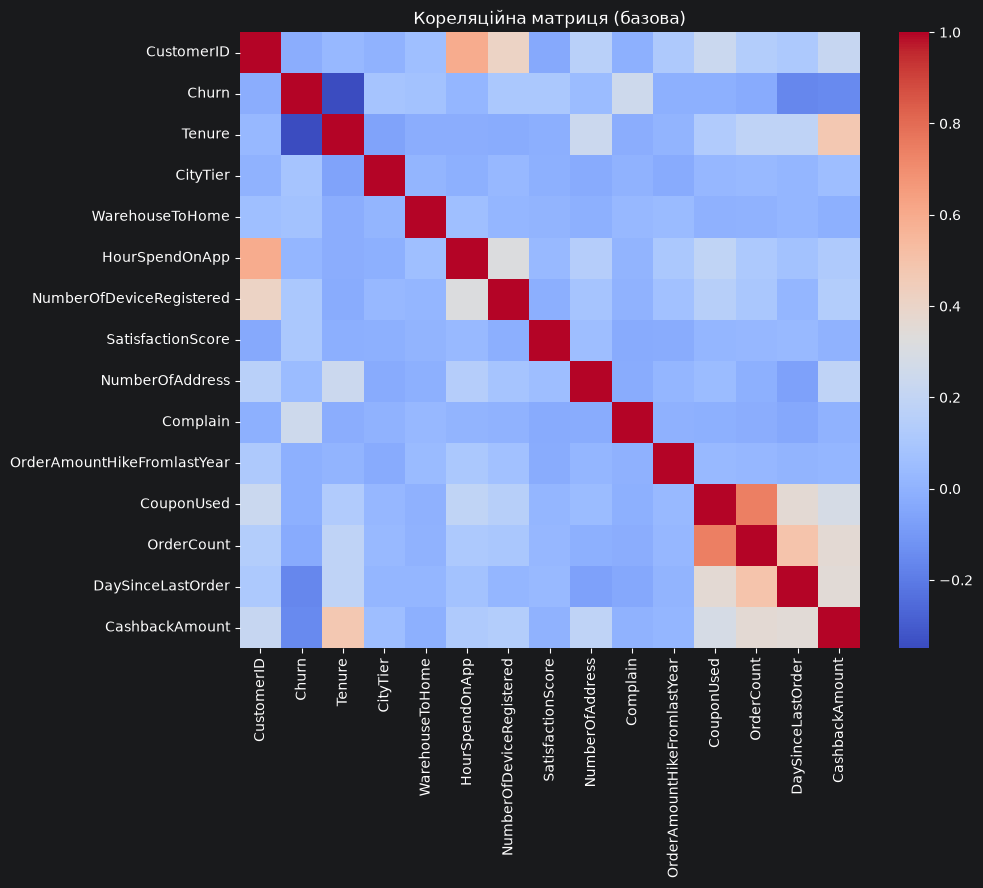

Відібрані ознаки (Filter): ['Tenure', 'NumberOfDeviceRegistered', 'Complain', 'DaySinceLastOrder', 'CashbackAmount']


In [9]:
# 5.1 Базова статистика
numeric_df = df.select_dtypes(include=[np.number])
corr_matrix = numeric_df.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=False, cmap='coolwarm')
plt.title('Кореляційна матриця (базова)')
plt.show()

# 5.2 Filter Selection
selector_filter = SelectKBest(f_classif, k=5)
X_num_imputed = numeric_df.drop(columns=['Churn', 'CustomerID']).fillna(0)
X_filtered = selector_filter.fit_transform(X_num_imputed, y)
selected_cols = X_num_imputed.columns[selector_filter.get_support()]
print("Відібрані ознаки (Filter):", selected_cols.tolist())